# CTDDG · PyTorch pretraining generators | **10 independent runs**

Samples from `Pretrained_no_toxicity` and `Pretrained_with_toxicity` only. Both checkpoints are **unconditional**; the 104 existing protein embeddings are used solely to enumerate test-set sample slots, **not** as inputs to these pretrained architectures.

- **Inputs:** existing embedding files and two PyTorch checkpoints in `REWORKED_CODE/model_weights`.
- **Outputs:** `testing/Validity_Analysis/Generated_104_10runs/<model>/proteinN/proteinN_all_samples.csv` (`Run_ID,SMILES`) and `proteinN_raw_attempts.csv`.
- **Protocol:** 104 slots × 10 independently seeded runs × 100 unique, sanitizable SMILES per model.
- **Resumption:** per-run immutable snapshots under `proteinN/runs/` permit safe restart. Incomplete snapshots trigger errors, never silent overwrites.
- **Not part of this notebook:** validity %, Ames toxicity, or property scoring (handled by the evaluation notebook).

Your original `Generated_104` folders remain untouched. Run on an allocated HPC compute node, not the Bhavani login node.

## 1 · Settings and output locations

The main CSV format is identical to Nitesh's output. Ten run IDs (1–10) are stored in the **same** `proteinN_all_samples.csv` per protein, with raw attempts in a separate file. Every model/protein/run is reproducibly seeded; seeds and checkpoint hashes are saved alongside each run.

In [1]:
from pathlib import Path
import sys, json, re, math, random, time, gc, hashlib, os
from dataclasses import dataclass

ROOT = Path('/home/muhamed/repo/CTDDG')
REWORKED = ROOT / 'REWORKED_CODE'
VALIDITY_ROOT = REWORKED / 'testing' / 'Validity_Analysis'
EMBEDDINGS_FOLDER = VALIDITY_ROOT / 'Embeddings_104' / 'embeddings_104'
WEIGHTS_ROOT = REWORKED / 'model_weights'
MODEL_ROOT = WEIGHTS_ROOT
ATOM_TYPES_PATH = REWORKED / 'chembl_preprocessed' / 'atom_types.txt'
OUTPUT_ROOT = VALIDITY_ROOT / 'Generated_104_10runs'

MODEL_NAMES = ['Pretrained_no_toxicity', 'Pretrained_with_toxicity']
TOTAL_RUNS = 10         # ten independent sampling runs per test-protein slot
TARGET_PER_RUN = 100   # unique, chemically sanitizable SMILES per run
BATCH_SIZE = 8
MAX_ACTIONS = 120
MAX_ATOMS = 120
MAX_ATTEMPTS_PER_RUN = 3000   # fail with partial logs if this limit is reached
SEED = 42   # each model/protein/run gets a distinct deterministic SHA-256-derived seed
GREEDY = False
SMOKE_TEST = False    # Change to True BEFORE first run for a 2-protein test
SMOKE_PROTEINS = 2
SMOKE_TARGET = 10
SMOKE_MAX_ATTEMPTS = 200
SAVE_RAW_EVERY_BATCHES = 5
SHOW_PROGRESS_EVERY_BATCHES = 5
SKIP_COMPLETE = True
TRUST_LOCAL_CHECKPOINT = True  # only load files from your own trusted training jobs

if SMOKE_TEST:
    effective_runs, effective_target = 1, SMOKE_TARGET
    effective_max_attempts = SMOKE_MAX_ATTEMPTS
    SAVE_ROOT = VALIDITY_ROOT / 'smoke_test_pytorch_10runs' / 'Generated_104_10runs'
else:
    effective_runs, effective_target = TOTAL_RUNS, TARGET_PER_RUN
    effective_max_attempts = MAX_ATTEMPTS_PER_RUN
    SAVE_ROOT = OUTPUT_ROOT

assert BATCH_SIZE >= 1 and MAX_ACTIONS >= 1 and MAX_ATOMS >= 1
assert effective_target > 0 and effective_runs > 0 and effective_max_attempts >= effective_target
print('Embeddings directory:', EMBEDDINGS_FOLDER)
print('Checkpoints:', WEIGHTS_ROOT)
print('Ordered PyTorch vocabulary:', ATOM_TYPES_PATH)
print('Output folder:', SAVE_ROOT)
assert OUTPUT_ROOT.name == 'Generated_104_10runs'
assert OUTPUT_ROOT != VALIDITY_ROOT / 'Generated_104'
print('MODE:', 'SMOKE TEST' if SMOKE_TEST else 'FULL (104 slots expected)')

Embeddings directory: /home/muhamed/repo/CTDDG/REWORKED_CODE/testing/Validity_Analysis/Embeddings_104/embeddings_104
Checkpoints: /home/muhamed/repo/CTDDG/REWORKED_CODE/model_weights
Ordered PyTorch vocabulary: /home/muhamed/repo/CTDDG/REWORKED_CODE/chembl_preprocessed/atom_types.txt
Output folder: /home/muhamed/repo/CTDDG/REWORKED_CODE/testing/Validity_Analysis/Generated_104_10runs
MODE: FULL (104 slots expected)


## 2 · Imports and environment check

Use your **existing PyTorch conda environment**. You need `torch`, `numpy`, `pandas`, `scipy`, `rdkit`, `ipykernel`, and Jupyter. MXNet and `bio-embeddings` are not needed.

In [2]:
import numpy as np
import pandas as pd
import scipy
from scipy import sparse
import torch
from torch import nn
from torch.nn import functional as F
from rdkit import Chem, RDLogger, rdBase
from rdkit.Chem import Draw
from IPython.display import display

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RDLogger.DisableLog('rdApp.error')
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__, '| device:', DEVICE)
print('RDKit:', rdBase.rdkitVersion, '| NumPy:', np.__version__, '| SciPy:', scipy.__version__)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
assert EMBEDDINGS_FOLDER.is_dir(), f'Embedding directory not found: {EMBEDDINGS_FOLDER}'
assert WEIGHTS_ROOT.is_dir(), f'Cannot find model_weights directory: {WEIGHTS_ROOT}'
assert ATOM_TYPES_PATH.is_file(), ('PyTorch atom vocabulary not found: ' + str(ATOM_TYPES_PATH) + '\n'
                                   'Use EXACTLY the atom_types.txt used for training; do not use the MXNet file blindly.')

Python: 3.11.16
PyTorch: 2.4.1+cu121 | device: cpu
RDKit: 2026.03.6 | NumPy: 2.4.6 | SciPy: 1.17.1


## 3 · Reuse all 104 existing embedding files

The embeddings have already been computed. Here we check their count and numeric shape, and use their **filenames** to enumerate the same test IDs as Nitesh's output. **Their contents are not passed to either unconditional PyTorch model.**

In [3]:
import numpy as np
import pandas as pd
from IPython.display import display

files = sorted(
    (p for p in EMBEDDINGS_FOLDER.glob('protein*.txt')
     if re.fullmatch(r'protein[0-9]+\.txt', p.name)),
    key=lambda p: int(p.stem.replace('protein', ''))
)
ids = [int(p.stem[7:]) for p in files]
expected = set(range(1, 105))
if set(ids) != expected or len(files) != 104:
    raise ValueError('Expected exactly protein1.txt ... protein104.txt. '
                     f'Missing: {sorted(expected - set(ids))}; extra: {sorted(set(ids)-expected)}; '
                     f'found {len(files)} files in {EMBEDDINGS_FOLDER}')

emb_rows=[]
for p in files:
    v = np.loadtxt(p, dtype=np.float32)
    if v.size == 0 or not np.isfinite(v).all():
        raise ValueError(f'Embedding file empty or contains NaN/Inf: {p}')
    if v.ndim not in (1, 2) or (v.ndim==2 and min(v.shape)!=1):
        raise ValueError(f'Unexpected embedding shape for {p.name}: {v.shape}')
    emb_rows.append({'protein_id':p.stem,'embedding_file':str(p),
                     'dimension':int(v.size),'embedding_sha256':hashlib.sha256(p.read_bytes()).hexdigest()})
embedding_manifest = pd.DataFrame(emb_rows)
if embedding_manifest.dimension.nunique() != 1:
    raise ValueError('Embedding dimensions differ across test IDs')
selected_files = files[:SMOKE_PROTEINS] if SMOKE_TEST else files
protein_ids = [p.stem for p in selected_files]
print('Embeddings verified:',len(files),'| vector dimension:',emb_rows[0]['dimension'])
print('Selected for generation:',len(protein_ids),'| first:',protein_ids[:6], '| last:',protein_ids[-3:])
print('Planned accepted molecules:',len(protein_ids)*len(MODEL_NAMES)*effective_runs*effective_target)
display(embedding_manifest.head(6))

Embeddings verified: 104 | vector dimension: 1024
Selected for generation: 104 | first: ['protein1', 'protein2', 'protein3', 'protein4', 'protein5', 'protein6'] | last: ['protein102', 'protein103', 'protein104']
Planned accepted molecules: 208000


,protein_id,embedding_file,dimension,embedding_sha256
0,protein1,/home/muhamed/repo/CTDDG/REWORKED_CODE/testing...,1024,4182ef59ff7f807b2ad63de24e6b1d1e9614c20ea4242e...
1,protein2,/home/muhamed/repo/CTDDG/REWORKED_CODE/testing...,1024,4182ef59ff7f807b2ad63de24e6b1d1e9614c20ea4242e...
2,protein3,/home/muhamed/repo/CTDDG/REWORKED_CODE/testing...,1024,4182ef59ff7f807b2ad63de24e6b1d1e9614c20ea4242e...
3,protein4,/home/muhamed/repo/CTDDG/REWORKED_CODE/testing...,1024,4182ef59ff7f807b2ad63de24e6b1d1e9614c20ea4242e...
4,protein5,/home/muhamed/repo/CTDDG/REWORKED_CODE/testing...,1024,4182ef59ff7f807b2ad63de24e6b1d1e9614c20ea4242e...
5,protein6,/home/muhamed/repo/CTDDG/REWORKED_CODE/testing...,1024,4182ef59ff7f807b2ad63de24e6b1d1e9614c20ea4242e...


## 4 · Load the **PyTorch training vocabulary**

The atom order used during pretraining must match the checkpoint. Never silently substitute the MXNet model's `atom_types.txt` solely because its length matches.

In [4]:
MAX_ITER_PER_MOL = 120
ATOM_TYPES_FILE = None
_mol_spec = None

def set_atom_vocab(path):
    global ATOM_TYPES_FILE, _mol_spec
    ATOM_TYPES_FILE = Path(path)
    if not ATOM_TYPES_FILE.is_file():
        raise FileNotFoundError(f'Atom vocabulary is required: {ATOM_TYPES_FILE}')
    _mol_spec = MoleculeSpec(ATOM_TYPES_FILE)
    return _mol_spec

class MoleculeSpec:
    def __init__(self, file_name):
        rows = []
        with Path(file_name).open(encoding='utf8') as f:
            for i,line in enumerate(f,1):
                if not line.strip(): continue
                parts = line.strip().split(',')
                if len(parts)!=3: raise ValueError(f'{file_name}:{i}: expected symbol,charge,explicitHs')
                rows.append((parts[0], int(parts[1]), int(parts[2])))
        if not rows or len(rows)!=len(set(rows)):raise ValueError('Empty or duplicated atom vocabulary')
        self.atom_types=rows
        self.atom_index={t:i for i,t in enumerate(rows)}
        self.bond_orders=[Chem.BondType.AROMATIC,Chem.BondType.SINGLE,Chem.BondType.DOUBLE,Chem.BondType.TRIPLE]
        self.bond_index={b:i for i,b in enumerate(self.bond_orders)}
        self.num_atom_types=len(self.atom_types)
        self.num_bond_types=len(self.bond_orders)
        self.max_iter=MAX_ITER_PER_MOL

    def get_atom_type(self, a):
        key=(a.GetSymbol(), a.GetFormalCharge(), a.GetNumExplicitHs())
        if key not in self.atom_index:raise ValueError(f'Out-of-vocabulary atom {key}; check atom_types.txt')
        return self.atom_index[key]

    def get_bond_type(self, b):
        bt=b.GetBondType()
        if bt not in self.bond_index:raise ValueError(f'Unsupported bond {bt}')
        return self.bond_index[bt]

    def index_to_atom(self, idx):
        symbol,charge,hs=self.atom_types[int(idx)]
        atom=Chem.Atom(symbol);atom.SetFormalCharge(charge);atom.SetNumExplicitHs(hs)
        return atom

    def index_to_bond(self, mol, begin_id, end_id, idx):
        mol.AddBond(int(begin_id),int(end_id),self.bond_orders[int(idx)])


def get_mol_spec():
    global _mol_spec
    if _mol_spec is None:_mol_spec=MoleculeSpec(ATOM_TYPES_FILE)
    return _mol_spec


def file_hash(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for c in iter(lambda:f.read(1<<20),b''):h.update(c)
    return h.hexdigest()


def get_d(A, X):

    _to_sparse = lambda _A, _X: sparse.coo_matrix((np.ones([_A.shape[0] * 2], dtype=np.int32),
                                                   (np.concatenate([_A[:, 0], _A[:, 1]], axis=0),
                                                    np.concatenate([_A[:, 1], _A[:, 0]], axis=0))),
                                                    shape=[_X.shape[0], ] * 2)   # this is creating a square matrtix of size len(X)


    A_sparse = _to_sparse(A, X)

    d2 = A_sparse * A_sparse
    d3 = d2 * A_sparse

    D_2 = np.stack(d2.nonzero(), axis=1)
    D_2 = D_2[D_2[:, 0] < D_2[:, 1], :]

    D_3 = np.stack(d3.nonzero(), axis=1)
    D_3 = D_3[D_3[:, 0] < D_3[:, 1], :]

    D_3_sparse = _to_sparse(D_3, X)
    D_3_sparse = D_3_sparse - D_3_sparse.multiply(A_sparse)
    D_3 = np.stack(D_3_sparse.nonzero(), axis=1)
    D_3 = D_3[D_3[:, 0] < D_3[:, 1], :]

    return D_2, D_3


def get_mol_from_graph(X, A, sanitize=True):
    try:
        mol = Chem.RWMol(Chem.Mol())

        X, A = X.tolist(), A.tolist()
        for i, atom_type in enumerate(X):
            mol.AddAtom(get_mol_spec().index_to_atom(atom_type))

        for atom_id1, atom_id2, bond_type in A:
            get_mol_spec().index_to_bond(mol, atom_id1, atom_id2, bond_type)
    except:
        return None

    if sanitize:
        try:
            mol = mol.GetMol()
            Chem.SanitizeMol(mol)
            return mol
        except:
            return None
    else:
        return mol


def get_mol_from_graph_list(graph_list, sanitize=True):
    mol_list = [get_mol_from_graph(X, A, sanitize) for X, A in graph_list]
    return mol_list


In [5]:
spec = set_atom_vocab(ATOM_TYPES_PATH)
print('Atom types:', spec.num_atom_types, '| bond types:', spec.num_bond_types)
print('Atom vocabulary SHA-256:', file_hash(ATOM_TYPES_PATH))
display(pd.DataFrame(spec.atom_types, columns=['symbol','charge','explicit_Hs']).head(12))

Atom types: 43 | bond types: 4
Atom vocabulary SHA-256: 98c9c49f5a4bfd8450a4d5a49681e0146cab8f2f9966d66658879a701471bb83


,symbol,charge,explicit_Hs
0,B,0,0
1,Br,0,0
2,Br,0,1
3,C,-1,0
4,C,-1,1
5,C,0,0
6,C,0,1
7,C,0,2
8,C,0,3
9,C,1,0


## 5 · PyTorch model definition and graph decoder

Reuse the `CTDDGPretrainer`, graph backbone, action policy, and incremental decoder from the PyTorch training/evaluation notebook. Strict state loading prevents silently missing weights.

In [6]:
def sum_segments(x, seg_id, count):
    result=x.new_zeros((count,)+x.shape[1:])
    return result.index_add(0,seg_id,x)


class LinearBN(nn.Module):
    def __init__(self, fin, fout):
        super().__init__()
        self.linear=nn.Linear(fin,fout,bias=False)
        self.bn=nn.BatchNorm1d(fout)
    def forward(self,x):return self.bn(self.linear(x))


class GraphConv(nn.Module):
    """CDGCN GC with one self term + one matrix per bond/distance relation."""
    def __init__(self, fin, fout, n_relations):
        super().__init__()
        self.W=nn.Parameter(torch.empty(fin*(1+n_relations),fout))
        nn.init.xavier_uniform_(self.W)
        self.n_relations=n_relations

    def forward(self,X,edge_lists):
        assert len(edge_lists)==self.n_relations
        terms=[X]
        for edge in edge_lists:
            if edge.numel()==0:terms.append(torch.zeros_like(X))
            else:
                terms.append(sum_segments(X[edge[1]],edge[0],X.shape[0]))
        return torch.cat(terms,dim=-1) @ self.W


class GraphBackbone(nn.Module):
    def __init__(self,n_atom,n_bond,D,F_e,F_h,F_skip,F_c):
        super().__init__()
        self.atom_embedding=nn.Embedding(n_atom,F_e)
        self.mask_embedding=nn.Embedding(3,F_e)
        self.convs=nn.ModuleList()
        self.pre_bns=nn.ModuleList()
        for i,fout in enumerate(F_h):
            fin=F_e if i==0 else F_h[i-1]
            self.pre_bns.append(nn.Identity() if i==0 else nn.BatchNorm1d(fin))
            self.convs.append(GraphConv(fin,fout,n_bond+D))
        self.bn_skip=nn.BatchNorm1d(sum(F_h))
        self.skip=LinearBN(sum(F_h),F_skip)
        self.dense=nn.ModuleList()
        for fin,fout in zip([F_skip]+F_c[:-1],F_c):self.dense.append(LinearBN(fin,fout))

    def forward(self,b):
        X=self.atom_embedding(b['X'])+self.mask_embedding(b['last_mask'])
        layer_out=[]
        for conv,bn in zip(self.convs,self.pre_bns):
            X=conv(F.relu(bn(X)) if not isinstance(bn,nn.Identity) else X,b['edges'])
            layer_out.append(X)
        X=F.relu(self.skip(F.relu(self.bn_skip(torch.cat(layer_out,dim=-1)))))
        for dense in self.dense:X=dense(X)
        return X


class Policy(nn.Module):
    def __init__(self,fin,hidden,n_atom,n_bond):
        super().__init__()
        self.n_atom=n_atom;self.n_bond=n_bond
        self.linear_h=LinearBN(fin*2,hidden)
        self.linear_h_t=LinearBN(fin,hidden)
        self.linear_x=nn.Linear(hidden,n_bond*(n_atom+1))
        self.linear_x_t=nn.Linear(hidden,1)

    def forward(self,X,b,X_end):
        nx_rep=b['NX_rep'];n_step=b['NX'].shape[0]
        node_state=torch.cat([X,X_end[nx_rep]],dim=-1)
        node_logits=self.linear_x(F.relu(self.linear_h(node_state)))
        end_logits=self.linear_x_t(F.relu(self.linear_h_t(X_end)))
        # Stable per-graph softmax over every (node, append/connect action) AND end.
        per_node_max=node_logits.max(dim=-1).values
        group_max=end_logits[:,0].clone()
        group_max=group_max.scatter_reduce(0,nx_rep,per_node_max,reduce='amax',include_self=True)
        node_weight=torch.exp(node_logits-group_max[nx_rep,None])
        end_weight=torch.exp(end_logits-group_max[:,None])
        denom=sum_segments(node_weight.sum(-1,keepdim=True),nx_rep,n_step)+end_weight
        soft_node=node_weight/denom[nx_rep]
        soft_end=(end_weight/denom)[:,0]
        connect=soft_node[:,:self.n_bond]
        append=soft_node[:,self.n_bond:].reshape(-1,self.n_atom,self.n_bond)
        return append,connect,soft_end


class CTDDGPretrainer(nn.Module):
    def __init__(self,n_atom,n_bond,D=2,F_e=16,F_h=(32,64,128,128,256,256),
                 F_skip=256,F_c=(512,),F_policy=128,n_rnn=3):
        super().__init__()
        self.n_atom=n_atom;self.n_bond=n_bond
        self.backbone=GraphBackbone(n_atom,n_bond,D,F_e,list(F_h),F_skip,list(F_c))
        self.rnn=nn.GRU(input_size=2*F_c[-1],hidden_size=F_c[-1],num_layers=n_rnn,batch_first=True)
        self.policy=Policy(F_c[-1],F_policy,n_atom,n_bond)
        self.init_atom_logits=nn.Parameter(torch.zeros(n_atom))
        # Original MXNet notebook initializes trainable matrices with Xavier.
        # Match that policy rather than PyTorch's default Kaiming/embedding init.
        for module in self.modules():
            if isinstance(module,(nn.Linear,nn.Embedding)):
                nn.init.xavier_uniform_(module.weight)
                if getattr(module,'bias',None) is not None:nn.init.zeros_(module.bias)
            elif isinstance(module,nn.GRU):
                for name,param in module.named_parameters():
                    if 'weight' in name:nn.init.xavier_uniform_(param)
                    elif 'bias' in name:nn.init.zeros_(param)
            elif isinstance(module,nn.BatchNorm1d):
                nn.init.ones_(module.weight);nn.init.zeros_(module.bias)

    def per_molecule_loglik(self,b):
        B,K=b['batch_size'],b['iw_size']
        X=self.backbone(b)
        n_step=b['NX'].numel()
        X_avg=sum_segments(X,b['NX_rep'],n_step)/b['NX'][:,None].to(X.dtype)
        X_last=X[b['NX_cum']-1]
        features=torch.cat([X_avg,X_last],dim=-1)
        # Padded sequences; gathering only actual step outputs means padding cannot change valid outputs.
        padded=features[b['graph_to_rnn']].reshape(B*K,-1,features.shape[-1])
        rnn_out,_=self.rnn(padded)
        rnn_out=rnn_out.reshape(B,K,-1,rnn_out.shape[-1])
        idx=b['rnn_to_graph']
        X_end=rnn_out[idx[:,0],idx[:,1],idx[:,2]]
        append,connect,end=self.policy(X,b,X_end)
        act=b['actions'];act_type=act[:,0]
        eps=1e-10
        init_logprob=F.log_softmax(self.init_atom_logits,dim=0)
        init_ll=init_logprob[b['action_0']]
        # indices in actions refer to global offset into concatenated graph nodes
        append_log=torch.log(append[act[:,3],act[:,1],act[:,2]]+eps)
        connect_log=torch.log(connect[act[:,4],act[:,2]]+eps)
        end_log=torch.log(end+eps)
        action_ll=torch.where(act_type==0,append_log,torch.where(act_type==1,connect_log,end_log))
        path_ll=sum_segments(action_ll[:,None],b['iw_ids'],B*K)[:,0] + init_ll
        path_ll=path_ll.reshape(B,K)-b['log_p_sigma'].reshape(B,K)
        return torch.logsumexp(path_ll,dim=1)-math.log(K)



print("PyTorch CTDDG architecture definitions loaded: GraphBackbone / Policy / CTDDGPretrainer")

PyTorch CTDDG architecture definitions loaded: GraphBackbone / Policy / CTDDGPretrainer


In [7]:
@dataclass
class _MolState:
    atoms: list
    bonds: list
    hidden: torch.Tensor
    last_action: int = 1          # 1 = init/append, 2 = connect
    actions: int = 0
    done: bool = False
    status: str = 'running'


def _graph_batch(states, device, bond_count=4):
    """Build EXACT same bond + D2 + D3 relation arrays as training's get_d()."""
    NX = np.asarray([len(st.atoms) for st in states], dtype=np.int64)
    X = np.asarray([atom for st in states for atom in st.atoms], dtype=np.int64)
    offsets = np.cumsum(np.pad(NX, (1, 0)))
    bond_rows = []
    mask = np.zeros((len(X),), dtype=np.int64)
    for i, st in enumerate(states):
        mask[offsets[i+1] - 1] = st.last_action
        bond_rows.extend((offsets[i]+u, offsets[i]+v, b) for u, v, b in st.bonds)
    A = np.asarray(bond_rows, dtype=np.int64).reshape((-1, 3))
    # Preserve the source pretraining exact sparse-walk definition; these are
    # NOT necessarily shortest-distance=2/3 sets.
    d2, d3 = get_d(A, X)
    relation_pairs = [A[A[:, 2] == b, :2] for b in range(bond_count)] + [d2, d3]
    edge_tensors = []
    for pairs in relation_pairs:
        if not len(pairs):
            edge_tensors.append(torch.empty((2, 0), dtype=torch.long, device=device))
        else:
            both = np.concatenate([pairs, pairs[:, ::-1]], axis=0)
            edge_tensors.append(torch.tensor(both.T.copy(), dtype=torch.long, device=device))
    return {'X': torch.tensor(X, dtype=torch.long, device=device),
            'last_mask': torch.tensor(mask, dtype=torch.long, device=device),
            'edges': edge_tensors,
            'NX': torch.tensor(NX, dtype=torch.long, device=device),
            'NX_rep': torch.repeat_interleave(torch.arange(len(NX), device=device),
                                               torch.tensor(NX, dtype=torch.long, device=device)),
            'NX_cum': torch.tensor(offsets[1:], dtype=torch.long, device=device)}


@torch.inference_mode()
def _decode_probabilities(model, states):
    """Single incremental GRU step for each unfinished molecular graph.

    Mirrors the model's *training* feature order [mean node embedding, last node
    embedding], the original MXNet stepwise inference, and the trained Policy.
    """
    if not states:
        return []
    device = next(model.parameters()).device
    batch = _graph_batch(states, device, model.n_bond)
    X = model.backbone(batch)
    n = batch['NX'].numel()
    mean_X = sum_segments(X, batch['NX_rep'], n) / batch['NX'][:, None].to(X.dtype)
    last_X = X[batch['NX_cum'] - 1]
    features = torch.cat([mean_X, last_X], dim=-1).unsqueeze(1)
    h0 = torch.stack([st.hidden for st in states], dim=1).contiguous()
    next_X, h1 = model.rnn(features, h0)
    ap, cn, en = model.policy(X, batch, next_X[:, 0, :])
    offsets = torch.cat([batch['NX'].new_zeros(1), batch['NX_cum']]).tolist()
    results = []
    for i, st in enumerate(states):
        st.hidden = h1[:, i, :].clone()
        sl = slice(offsets[i], offsets[i+1])
        results.append((ap[sl], cn[sl], en[i]))
    return results


def _draw_action(append, connect, end, generator=None, greedy=False):
    """Sample all (node, atom, bond), (node,bond), and END using joint probabilities."""
    n_app = append.numel()
    n_con = connect.numel()
    flat = torch.cat([append.reshape(-1), connect.reshape(-1), end.reshape(1)])
    if not torch.isfinite(flat).all() or torch.any(flat < 0):
        raise FloatingPointError('Invalid action distribution (NaN/Inf/negative probabilities)')
    z = flat.sum()
    if not torch.isfinite(z) or z.item() <= 0:
        raise FloatingPointError('Zero/invalid action probability mass')
    # Policy already normalizes all actions, but correct round-off prior to sampling.
    p = flat / z
    index = int(torch.argmax(p).item()) if greedy else int(torch.multinomial(p, 1, generator=generator).item())
    if index == n_app + n_con:
        return ('end',)
    if index >= n_app:
        local = index - n_app
        return ('connect', local // connect.shape[-1], local % connect.shape[-1])
    bond_count = append.shape[-1]
    atom_count = append.shape[-2]
    return ('append', index // (atom_count*bond_count),
            (index // bond_count) % atom_count, index % bond_count)



print("Graph builder, stepwise GRU decoder, and categorical action sampler defined.")

Graph builder, stepwise GRU decoder, and categorical action sampler defined.


## 6 · Strict checkpoint loading

`Pretrained_no_toxicity`: prefer `model_weights_final.pt` (fallback `checkpoint.pt`). `Pretrained_with_toxicity`: use `checkpoint.pt`. Model config and vocabulary hashes are checked when recorded in checkpoint metadata.

In [8]:
DEFAULT_CONFIG={'n_atom':spec.num_atom_types,'n_bond':spec.num_bond_types,'D':2,
                'F_e':16,'F_h':[32,64,128,128,256,256],'F_skip':256,
                'F_c':[512],'F_policy':128,'n_rnn':3}
CONFIG_KEYS=tuple(DEFAULT_CONFIG)
def read_checkpoint(model_name):
    folder=MODEL_ROOT/model_name
    candidates=([folder/'model_weights_final.pt',folder/'checkpoint.pt'] if model_name=='Pretrained_no_toxicity'
                else [folder/'checkpoint.pt'])
    checkpoint_path=next((p for p in candidates if p.is_file()),None)
    if checkpoint_path is None:raise FileNotFoundError(f'No checkpoint in {folder}')
    print('\nLoading:',model_name, checkpoint_path.name)
    try:
        obj=torch.load(checkpoint_path,map_location='cpu',weights_only=True)
    except Exception as exc:
        if not TRUST_LOCAL_CHECKPOINT:raise RuntimeError('Trusted checkpoint flag required for pickle-based weights') from exc
        print('weights_only=True failed; retrying trusted local checkpoint:',type(exc).__name__)
        obj=torch.load(checkpoint_path,map_location='cpu',weights_only=False)
    if not isinstance(obj,dict):raise TypeError('Expected a dictionary or state_dict in checkpoint')
    state=next((obj[k] for k in ('model','model_state_dict','state_dict') if isinstance(obj.get(k),dict)),obj)
    if not state or not all(isinstance(k,str) and isinstance(v,torch.Tensor) for k,v in state.items()):
        raise TypeError('Expected a dictionary of named tensor parameters')
    if all(k.startswith('module.') for k in state):state={k[7:]:v for k,v in state.items()}
    metadata={}
    for filename in ('run_meta.json','model_config.json'):
        p=folder/filename
        if p.is_file():
            data=json.loads(p.read_text())
            if isinstance(data,dict):
                metadata.update(data)
                print('Metadata:',p.name,'fields:',list(data)[:10])
    for expected_name in ('atom_types_sha256','atom_vocab_sha256'):
        expected=metadata.get(expected_name)
        if expected and file_hash(ATOM_TYPES_PATH)!=expected:
            raise ValueError(f'{model_name}: atom ordering/hash does not match training {expected_name}')
    saved_cfg=next((x for x in (metadata.get('model_config'),metadata.get('config'),metadata)
                    if isinstance(x,dict) and 'n_atom' in x),None)
    config=DEFAULT_CONFIG.copy()
    if saved_cfg:
        config.update({k:saved_cfg[k] for k in CONFIG_KEYS if k in saved_cfg})
        print('Model widths from training metadata.')
    else:
        print('No full config found: using reference architecture; strict loading will test compatibility.')
    if config['n_atom']!=spec.num_atom_types or config['n_bond']!=spec.num_bond_types:
        raise ValueError('Checkpoint config does not match the ordered PyTorch atom/bond vocabulary.')
    if config['D']!=2:raise ValueError('Reference decoder expects D=2 (D2 and D3 relations)')
    model=CTDDGPretrainer(**config)
    model.load_state_dict(state,strict=True)  # NEVER allow partial loads
    if any(not torch.isfinite(v).all() for v in model.state_dict().values() if torch.is_floating_point(v)):
        raise FloatingPointError('Checkpoint contains NaN/Inf weights.')
    model=model.to(DEVICE).eval()
    return model,checkpoint_path,metadata,config

for name in MODEL_NAMES:
    print(name,'weight files exist:',[(p.name,p.is_file()) for p in (MODEL_ROOT/name).glob('*.pt')])
print('Strict model loader ready; actual weights will be loaded in the next cell.')

Pretrained_no_toxicity weight files exist: [('checkpoint.pt', True), ('model_weights_final.pt', True)]
Pretrained_with_toxicity weight files exist: [('checkpoint.pt', True)]
Strict model loader ready; actual weights will be loaded in the next cell.


## 7 · Graph-to-SMILES export (not an evaluation)

Nitesh's generator saves **unique RDKit-sanitizable molecules**. This conversion is required to reproduce that CSV format. The full unfiltered attempts are separately preserved for subsequent chemical-validity analysis.

In [9]:
def convert_graph_for_output(st):
    """Attempt RDKit graph->canonical SMILES conversion; no metric is calculated."""
    try:
        rw = Chem.RWMol()
        for atom_id in st.atoms:
            rw.AddAtom(spec.index_to_atom(int(atom_id)))
        for u, v, b in st.bonds:
            rw.AddBond(int(u), int(v), spec.bond_orders[int(b)])
        mol = rw.GetMol()
        Chem.SanitizeMol(mol)
        return Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True), None
    except Exception as exc:
        return None, f'{type(exc).__name__}: {str(exc)[:180]}'

print('Graph-to-SMILES export conversion ready (no evaluation metrics).')

Graph-to-SMILES export conversion ready (no evaluation metrics).


## 8 · Sample graphs using the pretrained PyTorch policy

The pretrained model selects an initial atom and samples append/connect/end actions until it completes the molecular graph. Independent random seeds are used for each model, protein slot, and run. Failure and duplicate attempts are recorded but not scored here.

In [10]:
@torch.inference_mode()
def sample_batch(model, how_many, generator):
    p0 = F.softmax(model.init_atom_logits, dim=0)
    if not torch.isfinite(p0).all() or not (p0 >= 0).all():
        raise FloatingPointError('Invalid first-atom probability distribution')
    if GREEDY:
        choices = [int(torch.argmax(p0).item())] * how_many
    else:
        choices = torch.multinomial(p0, how_many, replacement=True, generator=generator).tolist()
    states = [_MolState(atoms=[int(a)], bonds=[],
                        hidden=torch.zeros(model.rnn.num_layers, model.rnn.hidden_size, device=DEVICE))
              for a in choices]
    for step in range(MAX_ACTIONS):
        active = [s for s in states if not s.done]
        if not active:
            break
        distributions = _decode_probabilities(model, active)
        for st, (append, connect, end) in zip(active, distributions):
            try:
                action = _draw_action(append, connect, end, generator=generator, greedy=GREEDY)
            except (RuntimeError, ValueError, FloatingPointError) as ex:
                st.done = True
                st.status = 'invalid_action_distribution'
                continue
            st.actions += 1
            if action[0] == 'end':
                st.done = True
                st.status = 'ended'
            elif action[0] == 'append':
                _, target, atom, bond = action
                if len(st.atoms) >= MAX_ATOMS:
                    st.done = True
                    st.status = 'max_atoms_exceeded'
                else:
                    st.bonds.append((int(target), len(st.atoms), int(bond)))
                    st.atoms.append(int(atom))
                    st.last_action = 1
            elif action[0] == 'connect':
                _, target, bond = action
                target, bond = int(target), int(bond)
                last = len(st.atoms) - 1
                if target == last:
                    st.done = True
                    st.status = 'self_bond'
                elif any({u, v} == {last, target} for u, v, _ in st.bonds):
                    st.done = True
                    st.status = 'duplicate_bond'
                else:
                    st.bonds.append((last, target, bond))
                    st.last_action = 2
    for st in states:
        if not st.done:
            st.done, st.status = True, 'max_actions_exceeded'
    return states


def stable_seed(*parts):
    key = '|'.join(map(str, parts))
    return int(hashlib.sha256(key.encode()).hexdigest()[:8], 16) % (2**31-1)


def atomic_csv(df, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp')
    df.to_csv(tmp, index=False)
    tmp.replace(path)


def collect_unique_samples(model, model_name, protein_id, run_id, target, max_attempts,
                           raw_path=None, accepted_path=None):
    seed = stable_seed(SEED, model_name, protein_id, run_id)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if DEVICE.type == 'cuda':
        torch.cuda.manual_seed(seed)
    generator = torch.Generator(device=DEVICE)
    generator.manual_seed(seed)

    chosen, seen, attempts = [], set(), []
    t0 = time.monotonic()
    batch_num = 0
    while len(chosen) < target and len(attempts) < max_attempts:
        batch_num += 1
        count = min(BATCH_SIZE, max_attempts - len(attempts))
        states = sample_batch(model, count, generator)
        for st in states:
            smiles, error = convert_graph_for_output(st)
            accepted = (st.status == 'ended' and smiles is not None and
                        smiles not in seen and len(chosen) < target)
            if accepted:
                seen.add(smiles)
                chosen.append({'Run_ID': run_id, 'SMILES': smiles})
            attempts.append({
                'Run_ID': run_id, 'Attempt_ID': len(attempts) + 1,
                'SMILES': smiles, 'decode_status': st.status,
                'saved_in_main_csv': bool(accepted),
                'atom_indices_json': json.dumps(st.atoms),
                'bond_indices_json': json.dumps(st.bonds),
                'conversion_error': error,
            })
        # Keep intermediates available if generation is interrupted.
        if batch_num % SAVE_RAW_EVERY_BATCHES == 0 or len(chosen) >= target:
            if raw_path is not None:
                atomic_csv(pd.DataFrame(attempts), raw_path)
            if accepted_path is not None:
                atomic_csv(pd.DataFrame(chosen, columns=['Run_ID', 'SMILES']), accepted_path)
        if (batch_num == 1 or batch_num % SHOW_PROGRESS_EVERY_BATCHES == 0 or
            len(chosen) >= target or len(attempts) >= max_attempts):
            print(f'    Run {run_id}: {len(chosen):>3}/{target} samples collected | '
                  f'{len(attempts):>4} attempts | '
                  f'{time.monotonic()-t0:.1f}s', flush=True)

    if raw_path is not None:
        atomic_csv(pd.DataFrame(attempts), raw_path)
    if accepted_path is not None:
        atomic_csv(pd.DataFrame(chosen, columns=['Run_ID','SMILES']), accepted_path)
    return pd.DataFrame(chosen, columns=['Run_ID', 'SMILES']), pd.DataFrame(attempts)


## 9 · Generate 10 runs with crash-safe per-run snapshots

One unique seed for every combination of checkpoint, test slot, and run. Each completed run is stored immutably under `proteinN/runs/`; the familiar combined CSVs are rebuilt from those verified snapshots. Existing complete files are reused only when seed, weights, vocabulary, configuration, and CSV hashes match. Partial or mismatched files are **never overwritten**.

In [11]:
def _json_write_atomic(payload, path):
    path=Path(path)
    path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(payload,indent=2,default=str))
    tmp.replace(path)

def _check_run_snapshot(run_dir, *, model_name, protein_id, run_id, expected_seed,
                        weight_hash, vocab_hash, target, max_attempts):
    accepted_file=run_dir/'accepted.csv'
    raw_file=run_dir/'raw_attempts.csv'
    info_file=run_dir/'run_info.json'
    paths=[accepted_file,raw_file,info_file]
    if not any(p.exists() for p in paths):
        return None
    if not all(p.is_file() for p in paths):
        raise FileExistsError(f'Incomplete run snapshot: {run_dir}; preserve/inspect before retrying.')
    meta=json.loads(info_file.read_text())
    required={'model':model_name,'protein_id':protein_id,'Run_ID':run_id,
              'seed':expected_seed,'checkpoint_sha256':weight_hash,
              'atom_types_sha256':vocab_hash,'target':target,
              'max_attempts':max_attempts,'max_actions':MAX_ACTIONS,'max_atoms':MAX_ATOMS,
              'greedy':GREEDY,'batch_size':BATCH_SIZE}
    if any(meta.get(k)!=v for k,v in required.items()):
        raise ValueError(f'Run snapshot configuration mismatch: {run_dir}')
    if meta.get('accepted_sha256')!=file_hash(accepted_file) or meta.get('raw_sha256')!=file_hash(raw_file):
        raise ValueError(f'Run snapshot CSV has changed since it was committed: {run_dir}')
    a=pd.read_csv(accepted_file,keep_default_na=False)
    r=pd.read_csv(raw_file,keep_default_na=False)
    if list(a.columns)!=['Run_ID','SMILES'] or len(a)!=target or a.SMILES.nunique()!=target:
        raise ValueError(f'Run snapshot accepted rows invalid: {run_dir}')
    required_raw={'Run_ID','Attempt_ID','SMILES','decode_status','saved_in_main_csv'}
    if not required_raw.issubset(r.columns) or len(r)==0 or not (r.Run_ID==run_id).all() or not (a.Run_ID==run_id).all():
        raise ValueError(f'Run snapshot raw rows invalid: {run_dir}')
    if len(r)!=meta.get('attempts') or len(a)!=meta.get('accepted'):
        raise ValueError(f'Run snapshot counts do not match metadata: {run_dir}')
    if r.Attempt_ID.tolist()!=list(range(1,len(r)+1)):
        raise ValueError(f'Run snapshot attempt IDs invalid: {run_dir}')
    from collections import Counter
    flags=r.saved_in_main_csv.astype(str).str.lower().isin(('true','1'))
    if Counter(r.loc[flags,'SMILES'])!=Counter(a.SMILES):
        raise ValueError(f'Run snapshot accepted flags and main CSV differ: {run_dir}')
    return a,r,meta

SAVE_ROOT.mkdir(parents=True,exist_ok=True)
all_summaries=[]
for model_name in MODEL_NAMES:
    print('\n'+'='*72+'\nMODEL: '+model_name,flush=True)
    model,weight_path,checkpoint_meta,config=read_checkpoint(model_name)
    with torch.inference_mode():
        first_atom=int(torch.argmax(F.softmax(model.init_atom_logits,dim=0)).item())
        state=_MolState([first_atom],[],torch.zeros(model.rnn.num_layers,
                        model.rnn.hidden_size,device=DEVICE))
        ap,co,en=_decode_probabilities(model,[state])[0]
        total_prob=float((ap.sum()+co.sum()+en).item())
        if not math.isfinite(total_prob) or abs(total_prob-1.0)>1e-4:
            raise ValueError(f'Invalid decoder probability sum: {total_prob}')
    print('PASS: strict checkpoint load and decoder check',flush=True)
    weight_hash=file_hash(weight_path)
    vocab_hash=file_hash(ATOM_TYPES_PATH)
    for i,protein_id in enumerate(protein_ids,1):
        dest=SAVE_ROOT/model_name/protein_id
        runs_dir=dest/'runs'
        runs_dir.mkdir(parents=True,exist_ok=True)
        main_file=dest/f'{protein_id}_all_samples.csv'
        raw_file=dest/f'{protein_id}_raw_attempts.csv'
        final_info=dest/f'{protein_id}_generation_info.json'
        print(f'[{i}/{len(protein_ids)}] {model_name}: {protein_id}',flush=True)
        accepted_parts=[];raw_parts=[];run_info=[]
        started=time.monotonic()
        for run_id in range(1,effective_runs+1):
            seed=stable_seed(SEED,model_name,protein_id,run_id)
            snapshot=runs_dir/f'run_{run_id:02d}'
            cached=_check_run_snapshot(snapshot,model_name=model_name,protein_id=protein_id,
                run_id=run_id,expected_seed=seed,weight_hash=weight_hash,
                vocab_hash=vocab_hash,target=effective_target,max_attempts=effective_max_attempts)
            if cached is None:
                if snapshot.exists() and any(snapshot.iterdir()):
                    raise FileExistsError(f'Unverified/partial run directory: {snapshot}; inspect before retrying')
                # Refuse to touch existing combined outputs with unknown provenance.
                if not accepted_parts and (main_file.exists() or raw_file.exists() or final_info.exists()):
                    if not any((runs_dir/f'run_{r:02d}'/'run_info.json').is_file()
                               for r in range(1,effective_runs+1)):
                        raise FileExistsError(f'Untracked existing output in {dest}. Choose new folder.')
                accepted,raw=collect_unique_samples(model,model_name,protein_id,run_id,
                    target=effective_target,max_attempts=effective_max_attempts)
                if len(accepted)!=effective_target:
                    # Preserve partial attempts separately; do not certify this run.
                    snapshot.mkdir(parents=True,exist_ok=True)
                    atomic_csv(accepted,snapshot/'PARTIAL_accepted.csv')
                    atomic_csv(raw,snapshot/'PARTIAL_raw_attempts.csv')
                    raise RuntimeError(f'{model_name}/{protein_id}/run{run_id}: '
                        f'{len(accepted)}/{effective_target} molecules after {len(raw)} attempts. '
                        'Partial run saved; do not publish as complete.')
                snapshot.mkdir(parents=True,exist_ok=True)
                if any(snapshot.iterdir()):
                    raise FileExistsError(f'Existing run data would be overwritten: {snapshot}')
                atomic_csv(accepted,snapshot/'accepted.csv')
                atomic_csv(raw,snapshot/'raw_attempts.csv')
                info={'model':model_name,'protein_id':protein_id,'Run_ID':run_id,
                    'seed':seed,'checkpoint_sha256':weight_hash,'atom_types_sha256':vocab_hash,
                    'target':effective_target,'max_attempts':effective_max_attempts,
                    'max_actions':MAX_ACTIONS,'max_atoms':MAX_ATOMS,'greedy':GREEDY,
                    'batch_size':BATCH_SIZE,'accepted':len(accepted),'attempts':len(raw),
                    'accepted_sha256':file_hash(snapshot/'accepted.csv'),
                    'raw_sha256':file_hash(snapshot/'raw_attempts.csv')}
                _json_write_atomic(info,snapshot/'run_info.json')
                print(f'  Run {run_id}/{effective_runs}: NEW '
                      f'{len(accepted)} accepted / {len(raw)} attempts | seed={seed}',flush=True)
            else:
                accepted,raw,info=cached
                print(f'  Run {run_id}/{effective_runs}: verified existing snapshot '
                      f'| seed={seed}',flush=True)
            accepted_parts.append(accepted)
            raw_parts.append(raw)
            run_info.append(info)
            # After each certified run, rebuild combined CSVs so intermediate output is inspectable.
            atomic_csv(pd.concat(accepted_parts,ignore_index=True),main_file)
            atomic_csv(pd.concat(raw_parts,ignore_index=True),raw_file)
        combined=pd.concat(accepted_parts,ignore_index=True)
        raw_combined=pd.concat(raw_parts,ignore_index=True)
        info={'model':model_name,'framework':'pytorch','protein_id':protein_id,
             'conditioned_on_protein':False,'embeddings_used_for_conditioning':False,
             'embedding_file':str(EMBEDDINGS_FOLDER/f'{protein_id}.txt'),
             'embedding_sha256':embedding_manifest.set_index('protein_id').loc[protein_id,'embedding_sha256'],
             'total_runs':effective_runs,'target_per_run':effective_target,
             'samples_saved':len(combined),'total_attempts':len(raw_combined),
             'elapsed_seconds_this_session':round(time.monotonic()-started,2),
             'per_run':[{'Run_ID':x['Run_ID'],'seed':x['seed'],'samples_saved':x['accepted'],
                         'generation_attempts':x['attempts']} for x in run_info],
             'checkpoint':str(weight_path),'checkpoint_sha256':weight_hash,
             'atom_types_sha256':vocab_hash,'base_seed':SEED,
             'max_actions':MAX_ACTIONS,'max_atoms':MAX_ATOMS,
             'smoke_test':SMOKE_TEST,'samples_csv':str(main_file),
             'raw_attempts_csv':str(raw_file)}
        _json_write_atomic(info,final_info)
        all_summaries.append(info)
        print(f'  -> COMPLETE: {len(combined)} accepted, {len(raw_combined)} attempts',flush=True)
    del model
    if torch.cuda.is_available():torch.cuda.empty_cache()
    gc.collect()

summary_df=pd.DataFrame([{k:v for k,v in d.items() if k!='per_run'} for d in all_summaries])
atomic_csv(summary_df,SAVE_ROOT/'pytorch_generation_inventory.csv')
print('Saved generation inventory:',SAVE_ROOT/'pytorch_generation_inventory.csv')
display(summary_df[['model','protein_id','samples_saved','total_attempts']].head(10))


MODEL: Pretrained_no_toxicity

Loading: Pretrained_no_toxicity model_weights_final.pt
Metadata: run_meta.json fields: ['schema_version', 'model', 'objective', 'model_config', 'k_paths', 'alpha', 'batch_size', 'seed', 'chembl_sha256', 'atom_types_sha256']
Metadata: model_config.json fields: ['n_atom', 'n_bond', 'D', 'F_e', 'F_h', 'F_skip', 'F_c', 'F_policy', 'n_rnn']
Model widths from training metadata.
PASS: strict checkpoint load and decoder check
[1/104] Pretrained_no_toxicity: protein1
    Run 1:   8/100 samples collected |    8 attempts | 13.9s
    Run 1:  40/100 samples collected |   40 attempts | 30.7s
    Run 1:  78/100 samples collected |   80 attempts | 40.1s
    Run 1: 100/100 samples collected |  104 attempts | 56.8s
  Run 1/10: NEW 100 accepted / 104 attempts | seed=523516355
    Run 2:   8/100 samples collected |    8 attempts | 5.3s
    Run 2:  40/100 samples collected |   40 attempts | 15.6s
    Run 2:  79/100 samples collected |   80 attempts | 23.9s
    Run 2: 100/100

[15:21:03] WARNING: could not find number of expected rings. Switching to an approximate ring finding algorithm.


    Run 8:  94/100 samples collected |  120 attempts | 4.9s
    Run 8: 100/100 samples collected |  128 attempts | 5.3s
  Run 8/10: NEW 100 accepted / 128 attempts | seed=1485053428
    Run 9:   7/100 samples collected |    8 attempts | 0.4s
    Run 9:  28/100 samples collected |   40 attempts | 1.7s
    Run 9:  58/100 samples collected |   80 attempts | 3.3s
    Run 9:  92/100 samples collected |  120 attempts | 4.9s
    Run 9: 100/100 samples collected |  128 attempts | 5.1s
  Run 9/10: NEW 100 accepted / 128 attempts | seed=916037534
    Run 10:   6/100 samples collected |    8 attempts | 0.3s
    Run 10:  31/100 samples collected |   40 attempts | 1.3s
    Run 10:  62/100 samples collected |   80 attempts | 3.6s
    Run 10:  89/100 samples collected |  120 attempts | 5.2s
    Run 10: 100/100 samples collected |  136 attempts | 5.9s
  Run 10/10: NEW 100 accepted / 136 attempts | seed=893831327
  -> COMPLETE: 1000 accepted, 1280 attempts
[78/104] Pretrained_with_toxicity: protein78
 

,model,protein_id,samples_saved,total_attempts
0,Pretrained_no_toxicity,protein1,1000,1064
1,Pretrained_no_toxicity,protein2,1000,1064
2,Pretrained_no_toxicity,protein3,1000,1048
3,Pretrained_no_toxicity,protein4,1000,1088
4,Pretrained_no_toxicity,protein5,1000,1056
5,Pretrained_no_toxicity,protein6,1000,1080
6,Pretrained_no_toxicity,protein7,1000,1080
7,Pretrained_no_toxicity,protein8,1000,1040
8,Pretrained_no_toxicity,protein9,1000,1104
9,Pretrained_no_toxicity,protein10,1000,1088


## 10 · Inspect saved CSV structure (no validity/toxicity calculation)

This checks only filenames and column layout and previews some molecules. Do your actual chemical validity, toxicity and Table 1/3 analysis in the separate evaluation notebook.


 Pretrained_no_toxicity | /home/muhamed/repo/CTDDG/REWORKED_CODE/testing/Validity_Analysis/Generated_104_10runs/Pretrained_no_toxicity/protein1/protein1_all_samples.csv
Saved: 1000 | Raw attempt log: protein1_raw_attempts.csv | exists: True


,Run_ID,SMILES
0,1,COn1c(CSCCO)nc2ccccc21
1,1,ClCc1nc2ccccc2c(Nc2ccccc2)c1Br
2,1,COc1ccc2cc(C=CC(=O)N3CCCCC3(C)C)[n+](C)cc2c1
3,1,COc1ccccc1-c1ccn(Cc2ccccc2)n1
4,1,COc1ccccc1CNc1nc2c(C)cccc2nc1O
5,1,Nc1ccccc1-c1nccc(OC2CCCCNC2)n1
6,1,Cc1ccccc1C(=O)C1(P(=O)(O)O)NC(=O)C1(C)C
7,1,CCCN1CCN2C(=O)CSc3ccccc3C2=C1C


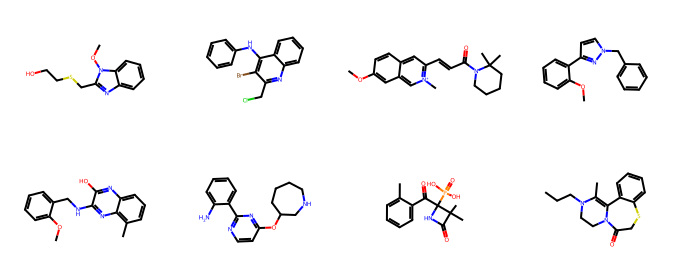


 Pretrained_with_toxicity | /home/muhamed/repo/CTDDG/REWORKED_CODE/testing/Validity_Analysis/Generated_104_10runs/Pretrained_with_toxicity/protein1/protein1_all_samples.csv
Saved: 1000 | Raw attempt log: protein1_raw_attempts.csv | exists: True


,Run_ID,SMILES
0,1,CN(C)CCN(C)CC(NC1CCCCC1)c1ccccc1O
1,1,CC(C)(c1ccccc1)c1ccnc(N2CCC3=CCC2C3=O)c1
2,1,CCN(C(=O)Nc1ccc(C(=O)NC(Cc2ccccc2)C(=O)O)cc1)C...
3,1,CCOc1ccc(NC(=O)COc2cc(C)cnn2)cc1
4,1,O=S(=O)(Nc1cccc(Br)c1)c1ccc(Cl)cc1
5,1,CCc1ccc(C(=O)NC(=O)Nc2ccccc2)cc1
6,1,O=C(NCC(F)(F)F)Nc1ccc(Cl)cn1
7,1,CNS(=O)(=O)c1ccc(O)c(Oc2ccc(Cl)c(F)c2C(=O)OC)c1


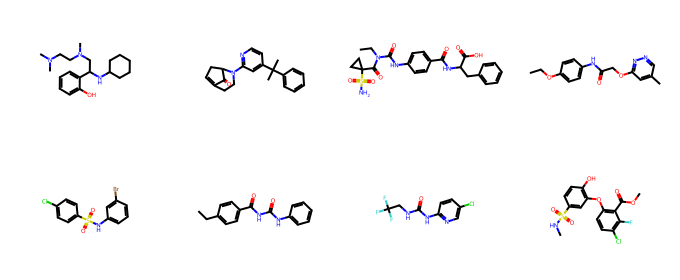

In [12]:
from rdkit.Chem import Draw
for model_name in MODEL_NAMES:
    protein_id=protein_ids[0]
    main=SAVE_ROOT/model_name/protein_id/f'{protein_id}_all_samples.csv'
    raw=SAVE_ROOT/model_name/protein_id/f'{protein_id}_raw_attempts.csv'
    df=pd.read_csv(main)
    assert list(df.columns)==['Run_ID','SMILES'], (main,list(df.columns))
    print('\n',model_name,'|',main)
    print('Saved:',len(df),'| Raw attempt log:',raw.name, '| exists:',raw.is_file())
    display(df.head(8))
    mols=[Chem.MolFromSmiles(s) for s in df.SMILES.head(8)]
    mols=[m for m in mols if m is not None]
    if mols:
        display(Draw.MolsToGridImage(mols,molsPerRow=4,subImgSize=(170,140)))

## 11 · Results folder and scientific interpretation

```text
/home/muhamed/repo/CTDDG/REWORKED_CODE/testing/Validity_Analysis/
├── Embeddings_104/embeddings_104/     # your existing protein1.txt ... protein104.txt
└── Generated_104_10runs/
    ├── nitesh_model/                   # your existing MXNet generation (untouched)
    │   └── protein1/protein1_all_samples.csv
    ├── Pretrained_no_toxicity/
    │   ├── protein1/protein1_all_samples.csv
    │   └── protein104/protein104_all_samples.csv
    └── Pretrained_with_toxicity/
        ├── protein1/protein1_all_samples.csv
        └── protein104/protein104_all_samples.csv
```

The PyTorch folders also contain `proteinN_raw_attempts.csv` (every attempted graph, including rejection causes) and `proteinN_generation_info.json` (checkpoint hashes, run settings, and `conditioned_on_protein=false`). A top-level `pytorch_generation_inventory.csv` summarizes file completeness **without computing evaluation scores**.

**Important validity caveat:** `proteinN_all_samples.csv` is prefiltered into exactly 100 unique, RDKit-sanitizable SMILES per run, just as in your MXNet notebook. Do **not** calculate raw generator validity using that filtered CSV alone. Use `proteinN_raw_attempts.csv` in the subsequent evaluation notebook. The original MXNet samples cannot reveal the number of rejected attempts unless that information was separately recorded.

**Important conditioning caveat:** all PyTorch samples are unconditional; the 104 files represent 104 independently seeded sample *groups*, not 104 protein-conditioned generations. In a comparative paper/table, label them as the **unconditional pretrained baselines**.
